# Solar Filament Segmentation 2026 — end-to-end pipeline (demo)

This notebook reproduces our submitted predictions from the weights stored in this repository (no training needed) and
walks through every stage on one test image. Out-of-fold PQ 0.4541 (organizers' evaluation, 707 training observations),
public leaderboard 0.40.

| stage | what happens | code |
|---|---|---|
| 1 pre-processing | solar disk (Otsu), limb-darkening flattening, full 2048 x 2048 | `preprocess` |
| 2 segmentation | mean of 15 U-Nets (ConvNeXt-T / EfficientNet-B4 / RegNetY-032 x 5 folds), mask + spine heads, h-flip TTA | `predict` |
| 3 instances | threshold, spine-guided merging, >= 400 px; faint candidates p > 0.3 | `candidate_sets` |
| 4 keep rule | 0.6 x mean of 5 CNN judges (x 5 folds) + 0.4 x GBM filter >= 0.4 | `judge_scores`, `m_f` |
| 5 boundary refiner | U-Net (5 folds, D4 TTA) re-draws every kept filament; overlaps go to the larger instance | `refine` |

Requirements: `pip install -r requirements.txt` (GPU recommended; about 6 s per image on one RTX 4080 SUPER, CPU works but
is slow). Data: the official competition data (`test/test_images`; `train/` only for the optional evaluation and training).

In [1]:
import os, sys, glob, time, numpy as np, pandas as pd, matplotlib.pyplot as plt
REPO = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'inference' else os.path.abspath('.')
DATA = (glob.glob('/kaggle/input/**/MAGFiLO_1.0_Kaggle_2026', recursive=True) + glob.glob(os.path.join(REPO, 'data', '**', 'MAGFiLO_1.0_Kaggle_2026'), recursive=True)
        + glob.glob('/root/autodl-tmp/data/MAGFiLO_1.0_Kaggle_2026'))[0]     # <- or set the path to the competition data here
TEST_DIR = os.path.join(DATA, 'test', 'test_images') + '/'
RUN_TRAINING = False          # True: retrain everything from scratch (many GPU hours, see section 6)
print('repo:', REPO, '| data:', DATA, '| test images:', len(os.listdir(TEST_DIR)))

repo: /root/repo | data: /root/autodl-tmp/data/MAGFiLO_1.0_Kaggle_2026 | test images: 180


## 1. Load the pipeline and all weights from the repository
`inference/predict_final.py` defines every stage; importing it loads 15 U-Nets, 25 CNN judges and 5 refiners from `weights/`
and refits the gradient-boosting filter on the stored out-of-fold candidate table (a few seconds).

In [2]:
sys.argv = ['predict_final.py', '--test_dir', TEST_DIR, '--weights', os.path.join(REPO, 'weights')]
os.environ['RUN_ALL'] = '0'                    # define the functions only; the full run is in section 3
__file__ = os.path.join(REPO, 'inference', 'predict_final.py')
exec(compile(open(__file__).read(), __file__, 'exec'))

test images: 180 | weights: /root/repo/weights/ | members: [['tu-convnext_tiny', 'cnxt'], ['tu-efficientnet_b4', 'effb4'], ['tu-regnety_032', 'regy']] | device: cuda


GBM filter refit on (9795, 13)


15 U-Nets, 25 CNN judges, 5 refiners loaded


## 2. One test image, stage by stage

20110120105534Ch.jpeg: 5 candidates -> 2 kept by the keep rule -> 2 refined filaments


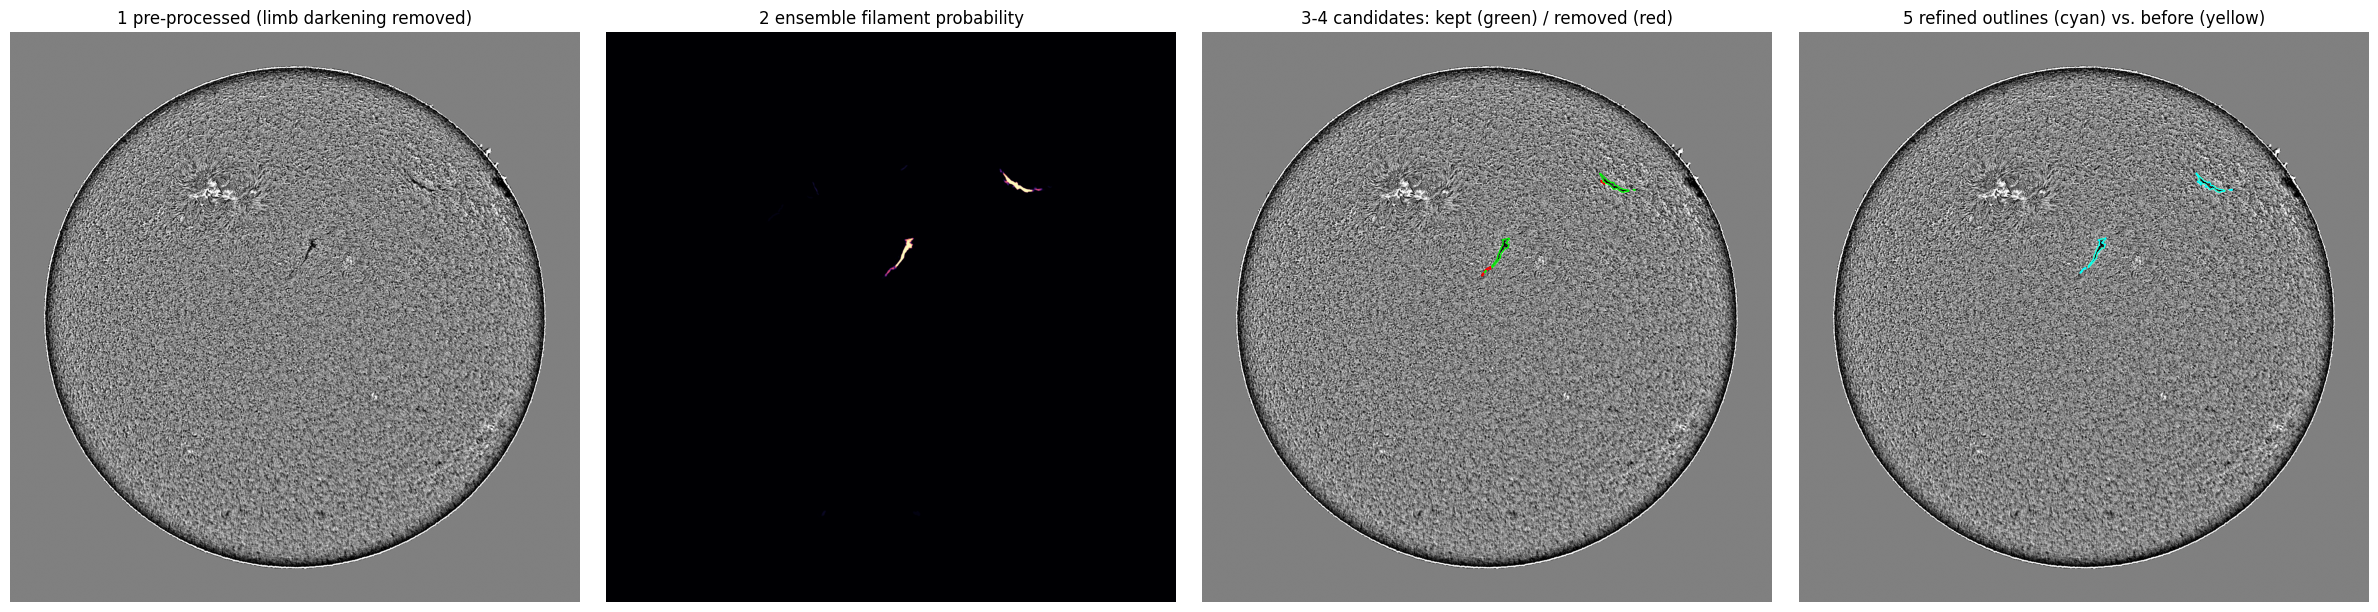

In [3]:
fn = sorted(os.listdir(TEST_DIR))[0]
final, st = run_image(TEST_DIR + fn)
print(f'{fn}: {len(st["cand"])} candidates -> {len(st["kept"])} kept by the keep rule -> {len(final)} refined filaments')
def outline(ax, masks, color, lw=0.8):
    import cv2
    for m in masks:
        for c in cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)[0]:
            c = c[:, 0]; ax.plot(np.r_[c[:, 0], c[0, 0]], np.r_[c[:, 1], c[0, 1]], color=color, lw=lw)
fig, axs = plt.subplots(1, 4, figsize=(24, 6))
axs[0].imshow(st['img'], cmap='gray'); axs[0].set_title('1 pre-processed (limb darkening removed)')
axs[1].imshow(st['P'][0], cmap='magma'); axs[1].set_title('2 ensemble filament probability')
axs[2].imshow(st['img'], cmap='gray'); outline(axs[2], [m for m, s in zip(st['cand'], st['score']) if s < THR], 'red')
outline(axs[2], st['kept'], 'lime'); axs[2].set_title('3-4 candidates: kept (green) / removed (red)')
axs[3].imshow(st['img'], cmap='gray'); outline(axs[3], st['kept'], 'yellow', 0.6); outline(axs[3], final, 'cyan')
axs[3].set_title('5 refined outlines (cyan) vs. before (yellow)')
for a in axs: a.axis('off')
plt.tight_layout(); plt.show()

## 3. Predict the whole test set -> submission.csv

In [4]:
from pycocotools import mask as mu
rows, t0 = [], time.time()
for n, fn in enumerate(sorted(os.listdir(TEST_DIR))):
    final, _ = run_image(TEST_DIR + fn)
    for q, m in enumerate(final):
        rows.append((f'{os.path.splitext(fn)[0]}_{q + 1}', mu.encode(np.asfortranarray(m.astype(np.uint8)))['counts'].decode()))
sub = pd.DataFrame(rows, columns=['filament_id', 'segmentation_rle']); sub.to_csv('submission.csv', index=False)
print(f'{len(sub)} filaments, {(time.time() - t0) / (n + 1):.1f} s per image -> submission.csv')

1059 filaments, 7.3 s per image -> submission.csv


## 4. Check against the submitted file
`results/submission_final.csv` is the file we submitted (public LB 0.40). The repository weights are stored in fp16, so a
few pixels can differ; we report how many predicted filaments are reproduced (IoU > 0.9 with a submitted one).

In [5]:
ref = pd.read_csv(os.path.join(REPO, 'results', 'submission_final.csv'))
img_of = lambda d: d.filament_id.str.rsplit('_', n=1).str[0]
sub['img'], ref['img'] = img_of(sub), img_of(ref)
rle = lambda s: {'size': [2048, 2048], 'counts': s.encode()}
best = []
for im, g in sub.groupby('img'):
    r = ref[ref.img == im]
    if len(r) == 0: best += [0.0] * len(g); continue
    T = np.asarray(mu.iou([rle(s) for s in g.segmentation_rle], [rle(s) for s in r.segmentation_rle], [0] * len(r)))
    best += list(T.max(1))
best = np.array(best)
print(f'ours {len(sub)} vs submitted {len(ref)} filaments; reproduced (IoU>0.9): {(best > 0.9).mean():.3f}, median IoU {np.median(best):.3f}')

ours 1059 vs submitted 1074 filaments; reproduced (IoU>0.9): 0.985, median IoU 0.997


## 5. Out-of-fold evaluation with the organizers' metric (training data)
`results/oof_final_predictions.csv` holds the pipeline's out-of-fold predictions for all 707 training observations
(every image predicted by models that never saw its month-fold). Scoring them with the organizers' rules gives the
numbers in the report; `tools/oof_viewer.py` also draws prediction-vs-annotation overlays.

final (refined) : {'PQ': np.float64(0.454131383304368), 'SQ': np.float64(0.6817753029666359), 'TP': 5105, 'FP': 2024, 'FN': 3094}
before refiner  : {'PQ': np.float64(0.4481215238440108), 'SQ': np.float64(0.6783336675371319), 'TP': 5063, 'FP': 2066, 'FN': 3136}


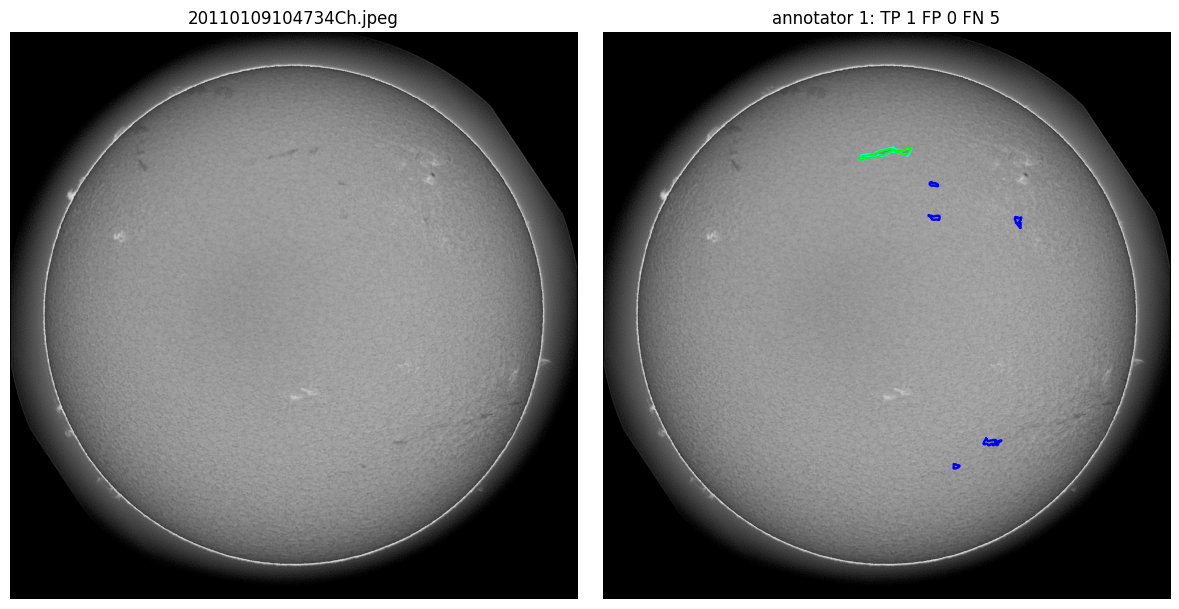

In [6]:
sys.path.insert(0, REPO)
from tools.oof_viewer import load_gt, load_pred, score_all, show
GT = load_gt(os.path.join(DATA, 'train', 'MAGFiLO_1.0_Annotations_kaggle2026_train.json'))
OOF = os.path.join(REPO, 'results', 'oof_final_predictions.csv')
print('final (refined) :', score_all(GT, load_pred(OOF)))
print('before refiner  :', score_all(GT, load_pred(OOF, 'rle_original')))
show(sorted(GT)[0], GT, load_pred(OOF), os.path.join(DATA, 'train', 'train_images') + '/')

## 6. Optional: training from scratch
Set `RUN_TRAINING = True` to retrain (many GPU hours; the scripts were run on a 32 GB GPU and expect the competition data
under `/root/autodl-tmp/data` — adjust `B` / paths at the top of each script for another machine):
1. `src/run.py` — one encoder, 5 month-grouped folds, out-of-fold maps (repeat for the three encoders);
2. `src/run_ens.py --ensemble ...` — ensemble maps, candidates, GBM filter table;
3. `stage2/vis_prep.py` — out-of-fold candidates and features; `stage2/cnn_filter.py` — the five CNN judges;
4. `stage2/refine.py crops / train / eval` — the boundary refiner (pycocotools-rasterised targets).

In [7]:
if RUN_TRAINING:
    import subprocess
    cmds = ['python src/run.py --encoder tu-convnext_tiny --tag cnxt --per_gpu 2',
            'python src/run.py --encoder tu-efficientnet_b4 --tag effb4 --per_gpu 2',
            'python src/run.py --encoder tu-regnety_032 --tag regy --per_gpu 2',
            'python src/run_ens.py --tag ens3 --eval_only --ensemble tu-convnext_tiny:cnxt,tu-efficientnet_b4:effb4,tu-regnety_032:regy',
            'python stage2/vis_prep.py',
            *[f'S={s} TAG={t} ARCH={a} python stage2/cnn_filter.py crops && S={s} TAG={t} ARCH={a} python stage2/cnn_filter.py train'
              for t, a, s in [('', 'resnet34', 128), ('_cnxt', 'convnext_tiny', 128), ('_effb3', 'efficientnet_b3', 128), ('_r50', 'resnet50', 128), ('_r34_192', 'resnet34', 192)]],
            'python stage2/refine.py crops && python stage2/refine.py train && python stage2/refine.py eval']
    for c in cmds:
        print('>>', c); subprocess.run(c, shell=True, cwd=REPO, check=True)
else:
    print('training skipped (RUN_TRAINING = False); the stored weights are used')

training skipped (RUN_TRAINING = False); the stored weights are used
